# LNG Supply Risk Analysis for a Fertilizer Plant
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aldo02032004/lng-supply-risk-analysis/blob/main/lng_supply_risk_analysis.ipynb)

**Energy risk management portfolio · Python · ISO 31000 · real market data**

**Summary.** This notebook estimates the cost risk of LNG supply for an ammonia-urea plant. The LNG price is indexed to Brent crude oil and paid in Indonesian Rupiah. It reports VaR, CVaR, Cost-at-Risk against the annual budget (RKAP), the effect of hedging, and monitoring status.

**Questions answered**
1. Which risks have the highest priority?
2. How far can next year's LNG cost exceed the budget?
3. How much does hedging reduce that risk?
4. What needs continuous monitoring (KRI, BCMS)?

| Section | ISO 31000 step | Content |
|---|---|---|
| 0 | Preparation | Assumptions, terms, setup |
| 1 | Identification | Risk register |
| 2 | Analysis | Market data, log returns, Monte Carlo simulation |
| 3 | Evaluation | Status against appetite, tolerance and budget |
| 4 | Treatment | Mitigation recommendations (Gemini), hedging effect |
| 5 | Monitoring | Volatility KRI, BCMS, change since last period |
| 6 | **Results** | **All key tables and charts in one place** |

Sections 0–5 only compute. To see the results, go straight to **section 6**.

**Note:** all parameters are hypothetical and can be changed in the `P` cell. Data: Brent from FRED, USD/IDR from Yahoo Finance. The Asian LNG spot price (JKM) is not used because it is licensed. This is a learning project, not investment advice.

## 0. Assumptions, terms and setup
Every value you may want to change lives in the `P` cell below. The values are **example assumptions** at a scale typical of the Indonesian fertilizer industry.

| Key | Definition | Value | Basis |
|---|---|---|---|
| `urea_cap` | Installed urea production capacity | 1,000,000 t/year | Scale of one new urea plant in Indonesia |
| `util` | Utilization: share of capacity actually used | 0.90 | About 330 operating days a year |
| `gas_per_ton` | Gas per ton of urea (feedstock + fuel) | 25 MMBtu/t | Modern plants use about 22–25 |
| `slope`, `const` | LNG price = `slope` × Brent + `const` (USD/MMBtu) | 0.12 and 1.5 | Oil-indexed Asian LNG contracts usually sit at 11–15% |
| `rkap` | Annual LNG cost budget (IDR trillion) | 6.0 | Example |
| `appetite`, `tolerance` | Highest green score and highest score before red | 6 and 12 | Set by management |
| `cost_tol` | How far cost may exceed the budget before red | 0.10 | Budget + 10% |
| `n_sims`, `horizon` | Number of scenarios and simulation length | 10,000 × 12 months | Annual budget cycle |
| `conf` | Confidence level for VaR and CVaR | 0.95 | Most common standard |
| `hedge` | Share of volume with a locked price | 0.50 | Partial hedge |
| `seed` | Random seed, so results are reproducible | 42 | Any value |
| `start` | First date of historical data | 2015-01-01 | About 11 years, covering several crises |
| `llm_model` | Gemini model for mitigation recommendations | gemini-3.6-flash | API key from `GOOGLE_API_KEY` |

**Key terms**

| Term | Meaning |
|---|---|
| Risk score | Likelihood (1–5) × Impact (1–5). Green ≤ appetite, yellow ≤ tolerance, red above |
| VaR 95% | A bad but plausible outcome: 95 of 100 scenarios cost less than this |
| CVaR 95% | Average cost of the worst 5% of scenarios |
| CaR | VaR minus a reference (budget or mean): how far the budget can be exceeded |
| KRI | Key risk indicator, an early warning signal; here, price volatility |
| RTO / MTPD | Target time to recover / maximum tolerable downtime |

In [1]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

sns.set_theme(style="whitegrid", font_scale=0.9)
pd.options.display.float_format = "{:,.2f}".format

P = dict(
    urea_cap=1_000_000, util=0.90,        # kapasitas urea (ton/tahun), utilisasi
    gas_per_ton=25,                       # MMBtu gas per ton urea (bahan baku + bahan bakar)
    slope=0.12, const=1.5,                # harga LNG (USD/MMBtu) = slope × Brent + const
    rkap=6.0,                             # anggaran biaya LNG setahun, Rp triliun (contoh)
    appetite=6, tolerance=12,             # batas skor L×I
    cost_tol=0.10,                        # biaya boleh melewati RKAP maksimum 10%
    n_sims=10_000, horizon=12, conf=0.95, hedge=0.50, seed=42, start="2015-01-01",
    llm_model="gemini-3.6-flash",         # model Gemini untuk rekomendasi mitigasi
)
mmbtu = P["urea_cap"] * P["util"] * P["gas_per_ton"]   # kebutuhan gas per tahun (MMBtu)

# --- Helper yang dipakai di banyak sel ---
rp = lambda x: f"Rp {x:.2f} T".replace(".", ",")                    # 6.24 → Rp 6,24 T
idn = lambda s: s.translate(str.maketrans(",.", ".,"))              # format angka Indonesia: 17,812.5 → 17.812,5
status = lambda x, hijau, kuning: np.select([x <= hijau, x <= kuning], ["HIJAU", "KUNING"], "MERAH")
tindakan = {"HIJAU": "Diterima, pantau rutin", "KUNING": "Pantau ketat, siapkan mitigasi", "MERAH": "Wajib mitigasi segera"}
nama = {"brent": "Minyak Brent", "usdidr": "Kurs USD/IDR"}
warna = {"brent": "#d62828", "usdidr": "#1d4e89"}                  # merah = minyak, biru tua = kurs

# --- Gemini: key dari Colab Secrets atau env GOOGLE_API_KEY. Tanpa key, notebook tetap jalan ---
try:
    from google import genai
    try:
        from google.colab import userdata
        key = userdata.get("GOOGLE_API_KEY")
    except ImportError:
        key = os.environ["GOOGLE_API_KEY"]
    llm = genai.Client(api_key=key)
except Exception as e:
    llm = None
    print(f"Gemini tidak aktif ({type(e).__name__}), kolom rekomendasi akan kosong.")
print(f"Kebutuhan LNG: {mmbtu/1e6:.1f} juta MMBtu/tahun (±{mmbtu/52/1e3:.0f} ribu ton)")

Gemini tidak aktif (ImportError), kolom rekomendasi akan kosong.
Kebutuhan LNG: 22.5 juta MMBtu/tahun (±433 ribu ton)


## 1. Identification: risk register
The risks that threaten LNG supply and cost. Each row holds a category, a **Likelihood (L)** and **Impact (I)** rating on a 1–5 scale, the risk **owner** and a deadline.

`L_lalu` and `I_lalu` are the ratings from the previous review period. They show which risks got worse or better. At the start of each period, copy the old `L`/`I` into `L_lalu`/`I_lalu`, then enter the new ratings. The values below are example judgements.

In [2]:
reg = pd.DataFrame([
    ("R01", "Harga Brent naik (harga LNG ikut naik)",    "Pasar",       4, 5, 4, 4, "Dept. Pengadaan Gas",    "2026-12-31"),
    ("R02", "Rupiah melemah terhadap USD",               "Keuangan",    4, 4, 3, 4, "Dept. Treasury",         "2026-12-31"),
    ("R03", "Kargo LNG terlambat, pabrik turun rate",    "Operasional", 3, 4, 3, 4, "Dept. Operasi Pabrik",   "2027-03-31"),
    ("R04", "Regasifikasi gangguan, pabrik amonia stop", "Operasional", 2, 5, 2, 5, "Dept. Operasi Pabrik",   "2027-06-30"),
    ("R05", "Force majeure pemasok LNG",                 "Pasokan",     2, 4, 3, 4, "Dept. Pengadaan Gas",    "2027-06-30"),
    ("R06", "Perubahan kebijakan HGBT / harga gas",      "Regulasi",    3, 4, 3, 3, "Dept. Hukum & Regulasi", "2027-03-31"),
    ("R07", "Tarif sewa kapal LNG naik",                 "Pasar",       2, 3, 3, 3, "Dept. Pengadaan Gas",    "2027-03-31"),
    ("R08", "Gagal bayar pihak lawan",                   "Kredit",      1, 4, 1, 4, "Dept. Treasury",         "2027-06-30"),
], columns=["id", "risiko", "kategori", "L", "I", "L_lalu", "I_lalu", "owner", "tenggat"])

## 2. Analysis
### 2.1 Market data
Downloads daily **Brent** prices (FRED, `DCOILBRENTEU`, USD/barrel) and the **USD/IDR** exchange rate (Yahoo Finance, `IDR=X`) from `start` to the latest available date. A copy is saved in `data/`, so the notebook falls back to the local file when a download fails.

Input validation: a Yahoo FX tick that deviates more than 4% from its 11-day median is treated as bad data and replaced by the previous value. Missing dates (for example market holidays) take the previous day's value.

In [3]:
def load(name, fetch):
    f = Path("data") / f"{name}.csv"                 # salinan lokal, mis. data/brent.csv
    try:
        s = fetch().dropna()                         # unduh data terbaru
        f.parent.mkdir(exist_ok=True); s.to_csv(f)   # simpan salinan
    except Exception as e:                           # internet mati, situs down, dll.
        print(f"{name}: unduhan gagal ({e}), pakai {f}")
        s = pd.read_csv(f, index_col=0, parse_dates=True).iloc[:, 0]
    return s

# FRED: CSV langsung tanpa API key. na_values="." karena FRED menandai data kosong dengan titik
fred = lambda sid: pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}&cosd={P['start']}",
                               index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
brent = load("brent", lambda: fred("DCOILBRENTEU"))
usdidr = load("usdidr", lambda: yf.download("IDR=X", start=P["start"], progress=False,
                                            auto_adjust=True)["Close"].squeeze())
px = pd.concat({"brent": brent, "usdidr": usdidr}, axis=1, sort=True)

# Validasi: tick kurs yang menyimpang > 4% dari median 11 hari = salah data, bukan pergerakan pasar
glitch = (px.usdidr / px.usdidr.rolling(11, center=True, min_periods=1).median() - 1).abs() > 0.04
px.loc[glitch, "usdidr"] = np.nan
px = px.ffill().dropna()                             # isi tanggal kosong, buang baris awal yang belum lengkap
print(f"{len(px):,} baris harian, {px.index[0]:%d %b %Y} s/d {px.index[-1]:%d %b %Y} "
      f"({glitch.sum()} tick kurs rusak diganti)")

3,088 baris harian, 02 Jan 2015 s/d 10 Nov 2026 (2 tick kurs rusak diganti)


### 2.2 Log returns and Monte Carlo simulation
A **log return** is the percentage change in price from one period to the next. Statistics and volatility come from daily returns.

The **Monte Carlo** step builds 10,000 possible "next years":
1. Daily prices are averaged per month and turned into monthly returns. The mean return is removed (*demeaned*), so the simulation does not bet on a price direction.
2. The starting point is the average of the last 90 trading days (about 4 months).
3. Each scenario draws **12 random months from history** (*bootstrap*). Brent and FX come from the same month, so their relationship is preserved.
4. Cost = volume × (slope × Brent + const) × FX, summed over 12 months → IDR trillion per year.

The simulation runs twice on the same market scenarios: **without hedging** and **with hedging** (part of the volume locked at the starting price).

In [4]:
ret = np.log(px).diff().dropna()                                    # log return harian
stats = (ret * 100).describe(percentiles=[.05, .5, .95]).T.rename(columns={"50%": "median"})
stats["vol tahunan"] = ret.std() * np.sqrt(252) * 100

def simulate(px, hedge=0.0):
    m = np.log(px.resample("ME").mean()).diff().dropna()           # log return bulanan
    X = (m - m.mean()).to_numpy()                                   # demean
    spot = px.tail(90).mean().to_numpy()                            # titik awal [brent, usdidr], ±4 bulan terakhir
    rng = np.random.default_rng(P["seed"])                          # seed sama → skenario sama antar-strategi
    shocks = rng.choice(X, size=(P["n_sims"], P["horizon"]))        # bootstrap 12 bulan acak dari sejarah
    paths = spot * np.exp(shocks.cumsum(axis=1))                    # jalur harga 12 bulan ke depan
    price = P["slope"] * paths[..., 0] + P["const"]                 # rumus kontrak: harga LNG USD/MMBtu
    price = hedge * (P["slope"] * spot[0] + P["const"]) + (1 - hedge) * price   # porsi hedge dikunci
    return (mmbtu / 12 * price * paths[..., 1]).sum(axis=1) / 1e12  # biaya setahun, Rp triliun

def metrics(c):
    var = np.quantile(c, P["conf"])
    return pd.Series({"Mean": c.mean(), "Median": np.median(c), "Std": c.std(),
                      "P5": np.quantile(c, .05), "VaR 95": var, "CVaR 95": c[c >= var].mean(),
                      "CaR vs RKAP": var - P["rkap"], "CaR vs mean": var - c.mean(),
                      "P(> RKAP)": (c > P["rkap"]).mean()})

cost = simulate(px)                          # 10.000 biaya, tanpa hedge
m = metrics(cost)
m_hedge = metrics(simulate(px, P["hedge"]))
assert m["CVaR 95"] >= m["VaR 95"] >= m["Median"] and simulate(px, hedge=1.0).std() < m["Std"]   # cek logika

## 3. Evaluation
Compares the analysis with the limits set by management:
- **Register risks:** score ≤ appetite → HIJAU (green), ≤ tolerance → KUNING (yellow), above → MERAH (red).
- **LNG cost:** VaR 95 ≤ budget → green, ≤ budget + `cost_tol` → yellow, above → red.

Each status has a standard action: green is monitored routinely, yellow is monitored closely, red must be mitigated now.

In [5]:
reg["skor"] = reg.L * reg.I
reg["skor_lalu"] = reg.L_lalu * reg.I_lalu
reg["status"] = status(reg.skor, P["appetite"], P["tolerance"])
reg["tindakan"] = reg.status.map(tindakan)

batas = P["rkap"] * (1 + P["cost_tol"])                             # batas toleransi biaya
cost_status = str(status(m["VaR 95"], P["rkap"], batas))

## 4. Treatment
**Mitigation recommendations:** all yellow and red risks go to Gemini in **one API call**, and Gemini returns one recommendation per risk. If Gemini is not available, the column shows "-". AI output must be reviewed by the risk owner before use.

The **hedging effect** is already computed in section 2.2 (`m_hedge`) and shown in section 6.

Hedging is simplified: no premium, no basis risk, no credit risk. Only the Brent price is locked, so FX risk remains.

In [6]:
todo = reg.query("status != 'HIJAU'")
prompt = ("Kamu analis manajemen risiko di pabrik pupuk (amonia-urea) Indonesia yang membeli LNG "
          "berindeks harga Brent dan membayar dalam Rupiah. Untuk tiap risiko di bawah, beri satu "
          "rekomendasi mitigasi yang konkret dan lazim di industri, maksimal 20 kata, bahasa Indonesia. "
          'Jawab hanya JSON dengan format {"ID risiko": "rekomendasi"}.\n\n'
          + "\n".join(f"{r.id}: {r.risiko} (skor {r.skor}, {r.status})" for r in todo.itertuples()))
try:
    resp = llm.models.generate_content(model=P["llm_model"], contents=prompt,
                                       config={"response_mime_type": "application/json"})
    reg["rekomendasi"] = reg.id.map(json.loads(resp.text)).fillna("-")   # risiko hijau: "-"
    sumber_rek = f"{P['llm_model']} (wajib direview risk owner)"
except Exception as e:
    reg["rekomendasi"] = "-"
    sumber_rek = f"belum ada rekomendasi (Gemini tidak dipakai: {type(e).__name__})"
print(f"Sumber rekomendasi: {sumber_rek}")

Sumber rekomendasi: belum ada rekomendasi (Gemini tidak dipakai: AttributeError)


## 5. Monitoring
- **Volatility KRI:** the 60-day volatility of each variable is compared with its own history. Below the 75th percentile is green, P75–P90 yellow, above P90 red (the 10% most turbulent periods).
- **BCMS (ISO 22301):** estimated downtime is compared with RTO and MTPD. An RTO of 72 hours is roughly the time to restart an ammonia plant. MTPD is roughly how long urea stock covers delivery obligations. Hours are example values.
- **Previous period:** every metric is recomputed with data up to the end of last month. For a quarterly comparison, change `"M"` to `"Q"`.

In [7]:
vol60 = ret.rolling(60).std().dropna() * np.sqrt(252)               # volatilitas 60 hari, tahunan
q = vol60.quantile([.75, .90])
kri = pd.DataFrame({"vol 60h sekarang %": vol60.iloc[-1], "P75 %": q.loc[.75], "P90 %": q.loc[.90]}) * 100
kri["status"] = [str(status(*r)) for r in kri.to_numpy()]

bcms = pd.DataFrame([("R04", "Regasifikasi gangguan, pabrik amonia stop", 120, 72, 336),
                     ("R03", "Kargo LNG terlambat",                        48, 72, 240)],
                    columns=["id", "skenario", "estimasi downtime (jam)", "RTO (jam)", "MTPD (jam)"])
bcms["status"] = status(bcms.iloc[:, 2], bcms.iloc[:, 3], bcms.iloc[:, 4])

lalu = px[px.index < px.index[-1].to_period("M").start_time]       # data sampai akhir bulan lalu
m_lalu = metrics(simulate(lalu))
v_lalu = vol60.loc[:lalu.index[-1]].iloc[-1]

## 6. Results
All key results are collected here:

| Subsection | Answers |
|---|---|
| 6.1 Summary and cost metrics | Overall status, and how far cost can exceed the budget |
| 6.2 Risk register | Which risks come first, what to do, who owns them, and what changed |
| 6.3 Hedging and monitoring | How much hedging cuts risk, KRI and BCMS status, change since last month |
| 6.4 Market data | Price history, return statistics and their distribution |
| 6.5 Dashboard | One-page summary for slides |

### 6.1 Summary and cost metrics

In [8]:
n = reg.status.value_counts()
print(f"RINGKASAN RISIKO LNG · data s/d {px.index[-1]:%d %b %Y}")
print(f"- Biaya LNG  : {cost_status}. VaR 95 {rp(m['VaR 95'])} vs RKAP {rp(P['rkap'])} "
      f"(batas toleransi {rp(batas)}). {tindakan[cost_status]}.")
print(f"- Register   : {n.get('MERAH', 0)} merah, {n.get('KUNING', 0)} kuning, {n.get('HIJAU', 0)} hijau")
print(f"- KRI        : " + ", ".join(f"{nama[c]} {kri.status[c]}" for c in kri.index))
print(f"- BCMS       : " + ", ".join(f"{r.id} {r.status}" for r in bcms.itertuples()))
print(f"- Hedge {P['hedge']:.0%}  : CaR vs RKAP {rp(m['CaR vs RKAP'])} → {rp(m_hedge['CaR vs RKAP'])}")

car = m["CaR vs RKAP"]
hasil = pd.DataFrame([
    ("Mean",        rp(m["Mean"]),    f"Rata-rata biaya LNG setahun {rp(m['Mean'])}"),
    ("Median",      rp(m["Median"]),  f"Separuh skenario di bawah {rp(m['Median'])}, separuh di atasnya"),
    ("Std",         rp(m["Std"]),     f"Biaya biasanya meleset ±{rp(m['Std'])} dari rata-rata"),
    ("P5",          rp(m["P5"]),      f"Skenario bagus: hanya 5% skenario lebih murah dari {rp(m['P5'])}"),
    ("VaR 95",      rp(m["VaR 95"]),  f"Skenario buruk yang wajar: 95 dari 100 skenario biayanya di bawah {rp(m['VaR 95'])}"),
    ("CVaR 95",     rp(m["CVaR 95"]), f"Kalau masuk 5% skenario terburuk, rata-rata biayanya {rp(m['CVaR 95'])}"),
    ("CaR vs RKAP", rp(car),          f"VaR − RKAP = {rp(m['VaR 95'])} − {rp(P['rkap'])}. "
                                      + (f"Kondisi buruk yang wajar bisa melampaui anggaran {rp(car)} ({car / P['rkap']:.0%} dari RKAP)"
                                         if car > 0 else "Kondisi buruk yang wajar pun masih di dalam anggaran")),
    ("CaR vs mean", rp(m["CaR vs mean"]), f"VaR − mean = {rp(m['VaR 95'])} − {rp(m['Mean'])}. "
                                          "Cadangan dana di atas biaya rata-rata untuk berjaga-jaga di kondisi buruk"),
    ("P(> RKAP)",   f"{m['P(> RKAP)']:.0%}", f"{m['P(> RKAP)']:.0%} dari 10.000 skenario biayanya melewati RKAP {rp(P['rkap'])}"),
], columns=["Metrik", "Hasil", "Penjelasan"]).set_index("Metrik")
print(f"\nMetrik biaya LNG 12 bulan tanpa hedge ({len(cost):,} skenario):".replace(",", "."))
with pd.option_context("display.max_colwidth", None):
    display(hasil)

RINGKASAN RISIKO LNG · data s/d 10 Nov 2026
- Biaya LNG  : MERAH. VaR 95 Rp 8,24 T vs RKAP Rp 6,00 T (batas toleransi Rp 6,60 T). Wajib mitigasi segera.
- Register   : 2 merah, 4 kuning, 2 hijau
- KRI        : Minyak Brent MERAH, Kurs USD/IDR KUNING
- BCMS       : R04 KUNING, R03 HIJAU
- Hedge 50%  : CaR vs RKAP Rp 2,24 T → Rp 0,95 T

Metrik biaya LNG 12 bulan tanpa hedge (10.000 skenario):


,Hasil,Penjelasan
Metrik,,
Mean,"Rp 5,91 T","Rata-rata biaya LNG setahun Rp 5,91 T"
Median,"Rp 5,77 T","Separuh skenario di bawah Rp 5,77 T, separuh di atasnya"
Std,"Rp 1,29 T","Biaya biasanya meleset ±Rp 1,29 T dari rata-rata"
P5,"Rp 4,06 T","Skenario bagus: hanya 5% skenario lebih murah dari Rp 4,06 T"
VaR 95,"Rp 8,24 T","Skenario buruk yang wajar: 95 dari 100 skenario biayanya di bawah Rp 8,24 T"
CVaR 95,"Rp 9,20 T","Kalau masuk 5% skenario terburuk, rata-rata biayanya Rp 9,20 T"
CaR vs RKAP,"Rp 2,24 T","VaR − RKAP = Rp 8,24 T − Rp 6,00 T. Kondisi buruk yang wajar bisa melampaui anggaran Rp 2,24 T (37% dari RKAP)"
CaR vs mean,"Rp 2,33 T","VaR − mean = Rp 8,24 T − Rp 5,91 T. Cadangan dana di atas biaya rata-rata untuk berjaga-jaga di kondisi buruk"
P(> RKAP),42%,"42% dari 10.000 skenario biayanya melewati RKAP Rp 6,00 T"


### 6.2 Risk register
Sorted by score, highest first. The last-month and this-month score columns show which risks got worse or better. Recommendations come from Gemini ("-" if Gemini is not available or the risk is green).

In [9]:
with pd.option_context("display.max_colwidth", None):
    display(reg.sort_values("skor", ascending=False).set_index("id")
               [["risiko", "L", "I", "skor_lalu", "skor", "status", "tindakan", "rekomendasi", "owner", "tenggat"]]
               .rename(columns={"risiko": "Risiko", "L": "Likelihood", "I": "Impact",
                                "skor_lalu": f"Skor {lalu.index[-1]:%b %Y}", "skor": f"Skor {px.index[-1]:%b %Y}",
                                "status": "Status", "tindakan": "Tindakan", "rekomendasi": "Rekomendasi",
                                "owner": "Owner", "tenggat": "Tenggat"}))
print(f"Sumber rekomendasi: {sumber_rek}")

,Risiko,Likelihood,Impact,Skor Oct 2026,Skor Nov 2026,Status,Tindakan,Rekomendasi,Owner,Tenggat
id,,,,,,,,,,
R01,Harga Brent naik (harga LNG ikut naik),4,5,16,20,MERAH,Wajib mitigasi segera,-,Dept. Pengadaan Gas,2026-12-31
R02,Rupiah melemah terhadap USD,4,4,12,16,MERAH,Wajib mitigasi segera,-,Dept. Treasury,2026-12-31
R03,"Kargo LNG terlambat, pabrik turun rate",3,4,12,12,KUNING,"Pantau ketat, siapkan mitigasi",-,Dept. Operasi Pabrik,2027-03-31
R06,Perubahan kebijakan HGBT / harga gas,3,4,9,12,KUNING,"Pantau ketat, siapkan mitigasi",-,Dept. Hukum & Regulasi,2027-03-31
R04,"Regasifikasi gangguan, pabrik amonia stop",2,5,10,10,KUNING,"Pantau ketat, siapkan mitigasi",-,Dept. Operasi Pabrik,2027-06-30
R05,Force majeure pemasok LNG,2,4,12,8,KUNING,"Pantau ketat, siapkan mitigasi",-,Dept. Pengadaan Gas,2027-06-30
R07,Tarif sewa kapal LNG naik,2,3,9,6,HIJAU,"Diterima, pantau rutin",-,Dept. Pengadaan Gas,2027-03-31
R08,Gagal bayar pihak lawan,1,4,4,4,HIJAU,"Diterima, pantau rutin",-,Dept. Treasury,2027-06-30


Sumber rekomendasi: belum ada rekomendasi (Gemini tidak dipakai: AttributeError)


### 6.3 Hedging and monitoring
- **Hedging effect:** same market scenarios, part of the volume locked at the starting price. The *Penurunan* (reduction) row shows how much each risk metric falls, in percent.
- **KRI** and **BCMS:** current monitoring status.
- **Change since last month:** metrics computed with data up to the end of last month, compared with today.

In [10]:
cols = ["Mean", "Std", "VaR 95", "CVaR 95", "CaR vs RKAP", "CaR vs mean", "P(> RKAP)"]
cmp = pd.DataFrame({"Tanpa hedge": m[cols], f"Hedge {P['hedge']:.0%}": m_hedge[cols]}).T
cmp["P(> RKAP)"] *= 100
cmp.loc["Penurunan (%)"] = (1 - cmp.iloc[1] / cmp.iloc[0]) * 100
print("Efek hedging (biaya dalam Rp triliun, P(> RKAP) dan penurunan dalam %):"); display(cmp)

print("\nKRI volatilitas 60 hari (%):"); display(kri)
print("\nBCMS:"); display(bcms.set_index("id"))

chg = pd.DataFrame({"Bulan lalu": m_lalu, "Sekarang": m}).loc[["Mean", "VaR 95", "CVaR 95", "CaR vs RKAP"]]
chg.loc["P(> RKAP) %"] = [m_lalu["P(> RKAP)"] * 100, m["P(> RKAP)"] * 100]
for col in vol60:
    chg.loc[f"Volatilitas {col} %"] = [v_lalu[col] * 100, vol60[col].iloc[-1] * 100]
chg["Perubahan"] = chg.Sekarang - chg["Bulan lalu"]
print(f"\nPerubahan sejak bulan lalu (data s/d {lalu.index[-1]:%d %b %Y}), biaya dalam Rp triliun:"); display(chg)

Efek hedging (biaya dalam Rp triliun, P(> RKAP) dan penurunan dalam %):


,Mean,Std,VaR 95,CVaR 95,CaR vs RKAP,CaR vs mean,P(> RKAP)
Tanpa hedge,5.91,1.29,8.24,9.20,2.24,2.33,42.01
Hedge 50%,5.80,0.63,6.95,7.40,0.95,1.15,32.72
Penurunan (%),1.87,50.99,15.73,19.54,57.82,50.81,22.11



KRI volatilitas 60 hari (%):


,vol 60h sekarang %,P75 %,P90 %,status
brent,67.50,40.78,60.70,MERAH
usdidr,13.13,10.51,13.58,KUNING



BCMS:


,skenario,estimasi downtime (jam),RTO (jam),MTPD (jam),status
id,,,,,
R04,"Regasifikasi gangguan, pabrik amonia stop",120,72,336,KUNING
R03,Kargo LNG terlambat,48,72,240,HIJAU



Perubahan sejak bulan lalu (data s/d 30 Oct 2026), biaya dalam Rp triliun:


,Bulan lalu,Sekarang,Perubahan
Mean,5.78,5.91,0.13
VaR 95,8.10,8.24,0.14
CVaR 95,8.99,9.20,0.21
CaR vs RKAP,2.10,2.24,0.14
P(> RKAP) %,37.44,42.01,4.57
Volatilitas brent %,64.34,67.50,3.16
Volatilitas usdidr %,8.15,13.13,4.98


### 6.4 Market data
- **Top chart:** Brent price history (left axis) and USD/IDR (right axis). The legend shows the change from the first to the last data point.
- **Bottom charts:** distribution of daily log returns. *Terburuk* (worst) = largest rise (cost goes up), *terbaik* (best) = largest fall (cost goes down), seen from the plant as an LNG buyer.

Statistik log return harian (%):


,count,mean,std,min,5%,median,95%,max,vol tahunan
brent,"3,087.00",0.02,3.12,-64.37,-4.11,0.01,3.92,41.20,49.47
usdidr,"3,087.00",0.01,0.62,-3.86,-0.88,0.01,0.93,4.58,9.86


Korelasi return harian Brent vs USD/IDR: +0,00


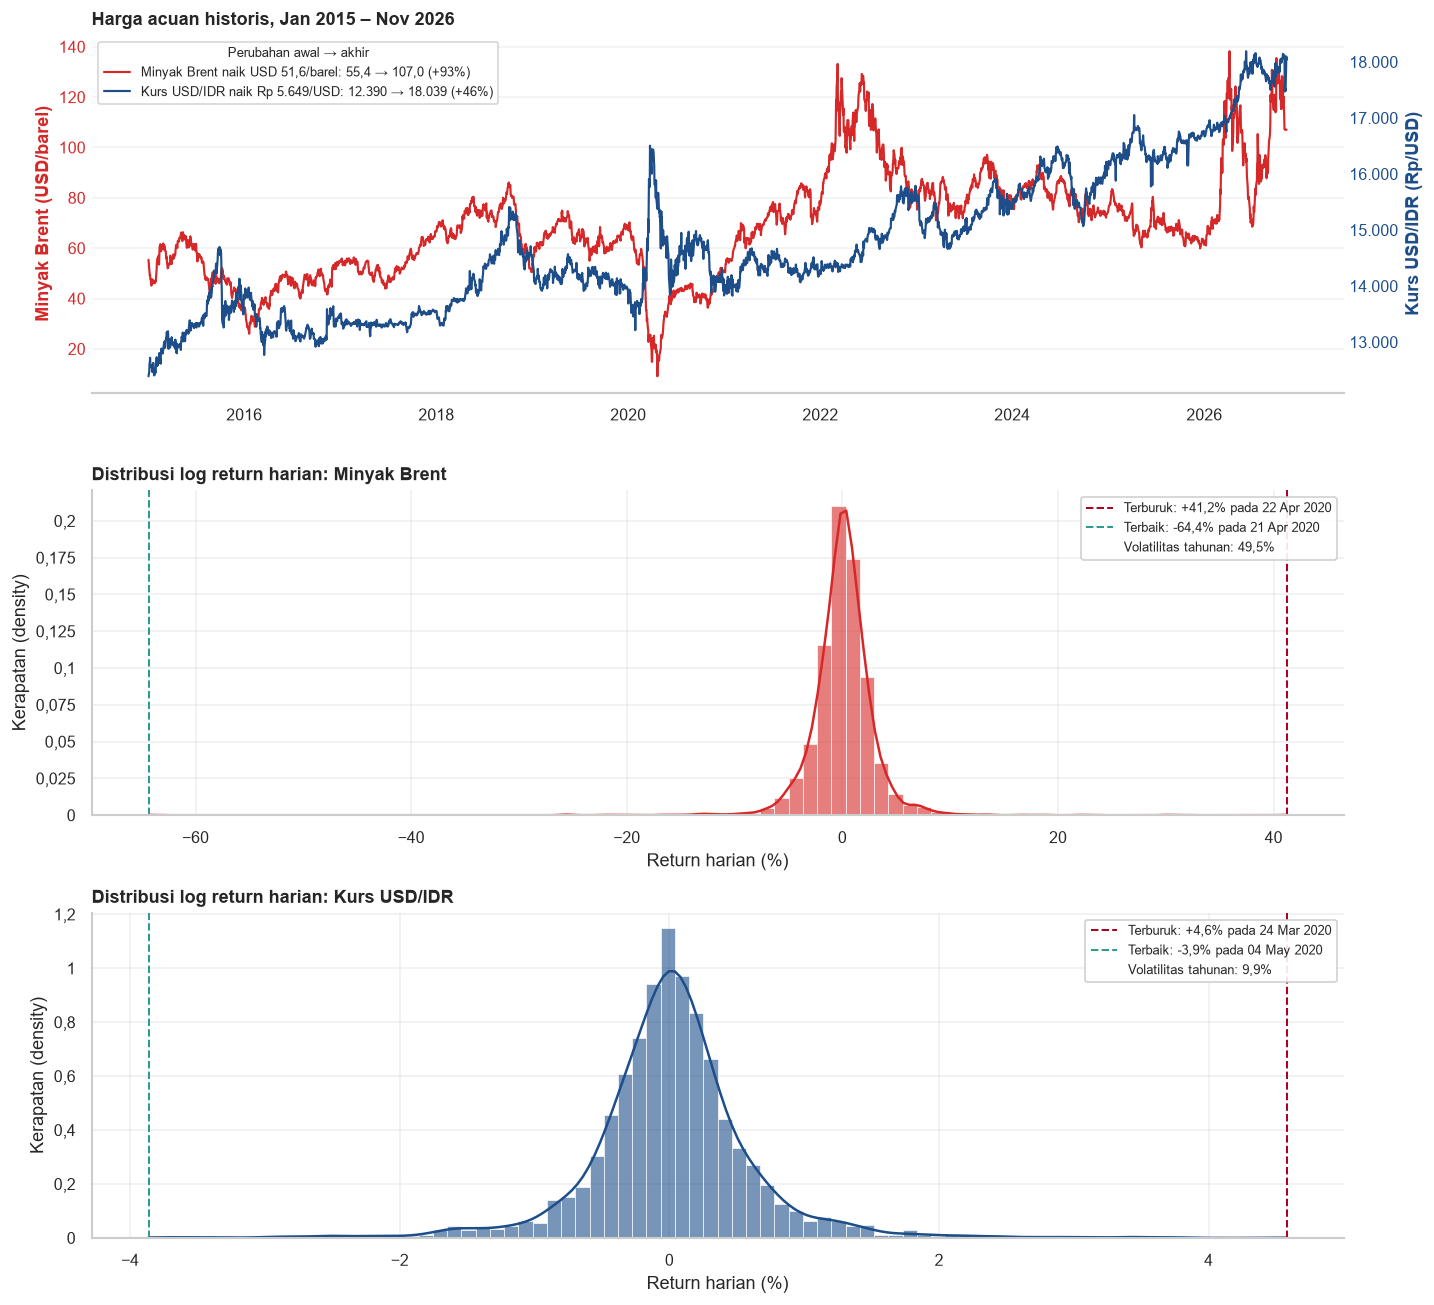

In [11]:
print("Statistik log return harian (%):"); display(stats)
print(f"Korelasi return harian Brent vs USD/IDR: {ret.corr().iloc[0, 1]:+.2f}".replace(".", ","))

fig, ax = plt.subplot_mosaic([["harga"], ["brent"], ["usdidr"]], figsize=(12, 11), dpi=120,
                             gridspec_kw={"height_ratios": [1.1, 1, 1]})

# (a) Sejarah harga: Brent sumbu kiri, kurs sumbu kanan
ax2 = ax["harga"].twinx()
for a, col, cur, unit, fmt in [(ax["harga"], "brent", "USD", "barel", ",.1f"), (ax2, "usdidr", "Rp", "USD", ",.0f")]:
    v0, v1 = px[col].iloc[[0, -1]]
    a.plot(px.index, px[col], color=warna[col], lw=1.3,
           label=idn(f"{nama[col]} {'naik' if v1 > v0 else 'turun'} {cur} {abs(v1 - v0):{fmt}}/{unit}: "
                     f"{v0:{fmt}} → {v1:{fmt}} ({v1 / v0 - 1:+.0%})"))
    a.set_ylabel(f"{nama[col]} ({cur}/{unit})", color=warna[col], fontweight="bold")
    a.tick_params(axis="y", colors=warna[col], length=0)
    a.spines[["top", "left", "right"]].set_visible(False)
    a.grid(False)
ax["harga"].grid(axis="y", alpha=0.25)
ax2.yaxis.set_major_formatter(lambda v, _: idn(f"{v:,.0f}"))
h1, l1 = ax["harga"].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax["harga"].legend(h1 + h2, l1 + l2, title="Perubahan awal → akhir", loc="upper left", fontsize=8,
                   title_fontsize=8, frameon=True, edgecolor="#cccccc")
ax["harga"].set_title(f"Harga acuan historis, {px.index[0]:%b %Y} – {px.index[-1]:%b %Y}", loc="left", fontweight="bold")

# (b, c) Distribusi log return harian
for col in ret:
    a, r = ax[col], ret[col] * 100
    sns.histplot(r, bins=80, stat="density", kde=True, color=warna[col], alpha=0.6, edgecolor="white", linewidth=0.4, ax=a)
    a.axvline(r.max(), color="#b00020", ls="--", lw=1.2, label=idn(f"Terburuk: {r.max():+.1f}% pada {r.idxmax():%d %b %Y}"))
    a.axvline(r.min(), color="#2a9d8f", ls="--", lw=1.2, label=idn(f"Terbaik: {r.min():+.1f}% pada {r.idxmin():%d %b %Y}"))
    a.plot([], [], " ", label=idn(f"Volatilitas tahunan: {r.std() * np.sqrt(252):.1f}%"))
    a.set_title(f"Distribusi log return harian: {nama[col]}", loc="left", fontweight="bold")
    a.set(xlabel="Return harian (%)", ylabel="Kerapatan (density)")
    a.legend(loc="upper right", fontsize=8, frameon=True, edgecolor="#cccccc", framealpha=0.9)
    a.yaxis.set_major_formatter(lambda v, _: idn(f"{v:g}"))
    a.grid(alpha=0.3); sns.despine(ax=a)
plt.tight_layout(); plt.show()

### 6.5 Dashboard
One page for slides: the **risk matrix** (colors from appetite/tolerance), the 12-month **cost distribution** against the budget, and the **volatility KRI** with the red threshold at P90.

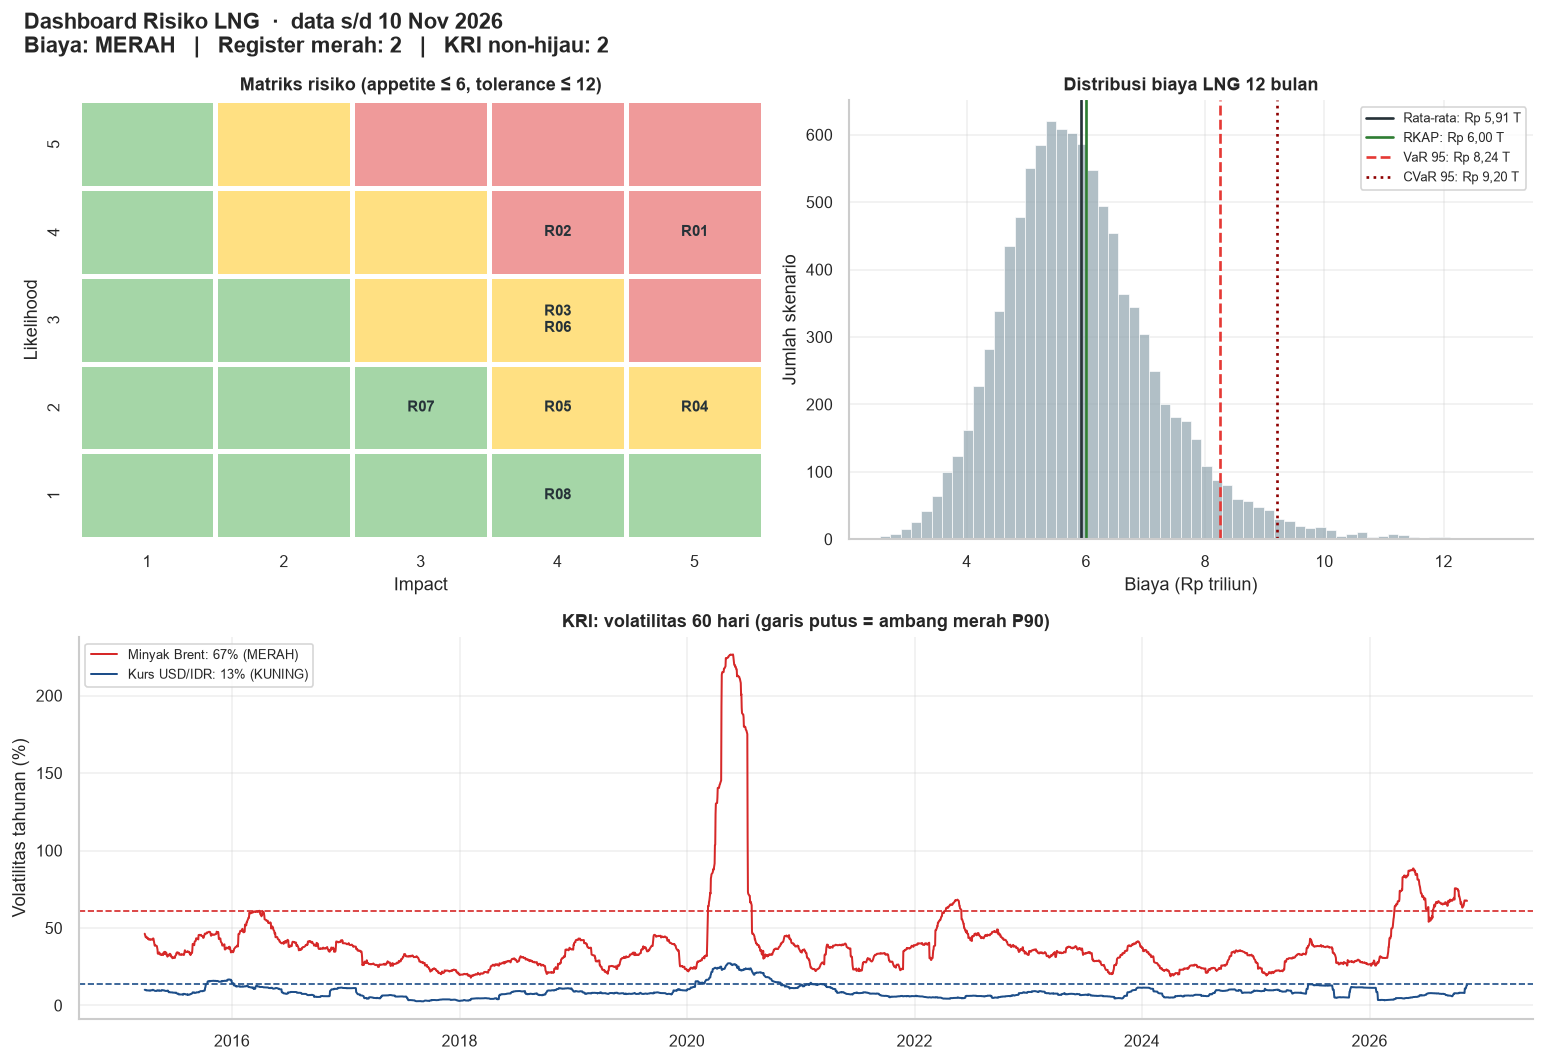

In [12]:
fig, ax = plt.subplot_mosaic([["heat", "cost"], ["kri", "kri"]], figsize=(13, 9), dpi=120,
                             gridspec_kw={"height_ratios": [1.15, 1]})
fig.suptitle(f"Dashboard Risiko LNG  ·  data s/d {px.index[-1]:%d %b %Y}\n"
             f"Biaya: {cost_status}   |   Register merah: {(reg.status == 'MERAH').sum()}   |   "
             f"KRI non-hijau: {(kri.status != 'HIJAU').sum()}", fontsize=13, fontweight="bold", x=0.02, ha="left")

# (a) Matriks risiko 5×5
L, I = np.meshgrid(range(5, 0, -1), range(1, 6), indexing="ij")
codes = np.vectorize({"HIJAU": 0, "KUNING": 1, "MERAH": 2}.get)(status(L * I, P["appetite"], P["tolerance"]))
labels = [["\n".join(reg.id[(reg.L == l) & (reg.I == i)]) for i in range(1, 6)] for l in range(5, 0, -1)]
sns.heatmap(codes, annot=labels, fmt="", cmap=["#a5d6a7", "#ffe082", "#ef9a9a"], cbar=False, vmin=0, vmax=2,
            linewidths=2, linecolor="white", xticklabels=range(1, 6), yticklabels=range(5, 0, -1),
            annot_kws={"fontsize": 9, "weight": "bold", "color": "#263238"}, ax=ax["heat"])
ax["heat"].set(title=f"Matriks risiko (appetite ≤ {P['appetite']}, tolerance ≤ {P['tolerance']})",
               xlabel="Impact", ylabel="Likelihood")

# (b) Distribusi biaya 12 bulan vs RKAP
sns.histplot(cost, bins=60, color="#90a4ae", alpha=0.7, edgecolor="white", linewidth=0.4, ax=ax["cost"])
for val, lab, c, ls in [(m["Mean"], "Rata-rata", "#263238", "-"), (P["rkap"], "RKAP", "#2e7d32", "-"),
                        (m["VaR 95"], "VaR 95", "#e53935", "--"), (m["CVaR 95"], "CVaR 95", "#8e0000", ":")]:
    ax["cost"].axvline(val, color=c, ls=ls, lw=1.6, label=f"{lab}: {rp(val)}")
ax["cost"].set(title="Distribusi biaya LNG 12 bulan", xlabel="Biaya (Rp triliun)", ylabel="Jumlah skenario")
ax["cost"].legend(fontsize=8, frameon=True, edgecolor="#cccccc")

# (c) KRI volatilitas 60 hari, garis putus = ambang merah P90
for col in vol60:
    ax["kri"].plot(vol60.index, vol60[col] * 100, color=warna[col], lw=1.2,
                   label=f"{nama[col]}: {vol60[col].iloc[-1] * 100:.0f}% ({kri.status[col]})")
    ax["kri"].axhline(q.loc[.90, col] * 100, color=warna[col], ls="--", lw=1)
ax["kri"].set(title="KRI: volatilitas 60 hari (garis putus = ambang merah P90)", ylabel="Volatilitas tahunan (%)")
ax["kri"].legend(fontsize=8, loc="upper left", frameon=True, edgecolor="#cccccc")

for a in ax.values():
    a.title.set(fontsize=11, fontweight="bold")
    if a is not ax["heat"]:
        a.grid(alpha=0.3); sns.despine(ax=a)
plt.tight_layout(); plt.show()

## Limitations
- Plant, contract, budget, appetite/tolerance, register and BCMS values are examples. Appetite and tolerance are management decisions, not model outputs.
- Brent is a proxy for the LNG price, because the Asian LNG spot price (JKM) is licensed.
- The bootstrap treats months as independent, so seasonality and mean reversion are not captured.
- Hedging is simplified: no premium, basis risk or credit risk.
- Gemini recommendations are suggestions and must be reviewed by the risk owner.

To adapt this notebook to another commodity or industry, see the *Adapting to another case* section in the README.